# Optimización de CROP4

Optuna maximiza `acc_both` (la proporción de mezclas con ambas clases acertadas) sobre 1000 mezclas fijas de entrenamiento de Fashion-MNIST. Cada prueba ejecuta 20 iteraciones de separación con proyección ponderada por confianza. Se fija `beta=1` y se toman `alpha_1` y `alpha_2` de los valores por defecto de CROP4.

In [1]:
from datetime import datetime
import sys
from pathlib import Path

import numpy as np
import tensorflow as tf
import optuna

project_root = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "project" / "CROP" / "models").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from project.loader import Loader
from project.CROP.models.crop4 import Crop4

SEED = 3333
DATASET = "fashion"
CVAE_NAME = "int_256_lat_64_beta_0_4_fashion.keras"
PREDICTOR_NAME = f"CCE_Conv2D_{DATASET}.keras"
N_IMAGES = 1000
N_TRIALS = 100
N_VALIDATION_IMAGES = 1000
N_VALIDATION_RUNS = 3
TARGET_METRIC = "acc_both"
SEPARATION_ITERATIONS = 20
assert TARGET_METRIC in {"acc_both", "ssim", "recon_bpsnr"}

tf.keras.utils.set_random_seed(SEED)
data = Loader.data(dataset=DATASET)
cvae = Loader.cvae(model_name=CVAE_NAME)
predictor = Loader.predictor(model_name=PREDICTOR_NAME)

# Generador independiente de las semillas del CVAE y de Optuna.
rng = np.random.default_rng(SEED)
idx0 = rng.permutation(len(data["x_train"]))[:N_IMAGES]
idx1 = rng.permutation(len(data["x_train_1"]))[:N_IMAGES]
train_batch = (
    data["x_train"][idx0], data["x_train_1"][idx1],
    data["y_train"][idx0], data["y_train_1"][idx1],
)


def scalar_metric(metrics, key):
    value = metrics[key]
    # Las métricas de calidad devuelven (media, desvío).
    if isinstance(value, (tuple, list)):
        value = value[0]
    return float(value)

2026-11-23 16:50:22.633200: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-23 16:50:22.637564: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-23 16:50:22.669950: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-23 16:50:22.689992: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795463422.722158 1484959 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795463422.72

Usando fashion como dataset


2026-11-23 16:50:25.792826: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Espacio de búsqueda

Se ajustan `delta` entre 0 y 1 y `bias` entre 0.05 y 0.45 en escala lineal. `confidence_floor` y `confidence_scale` se ajustan entre 0.01 y 1, y `slope` entre 5 y 60, en escala logarítmica.

In [2]:
metric_names = ("acc_both", "ssim", "recon_bpsnr")
fixed_params = {
    **Crop4(cvae=cvae, predictor=predictor).default_params,
    "beta": 1.0,
}


def evaluate(batch, params, seed):
    tf.keras.utils.set_random_seed(seed)
    model = Crop4(cvae=cvae, predictor=predictor)
    metrics = model.unmix(
        *batch,
        params=params,
        iterations=SEPARATION_ITERATIONS,
        labels=data["labels"],
        show_image=False,
        show_metrics=False,
    )
    return {key: scalar_metric(metrics, key) for key in metric_names}


def objective(trial):
    params = {
        **fixed_params,
        "delta": trial.suggest_float("delta", 0.0, 1.0),
        "bias": trial.suggest_float("bias", 0.05, 0.45),
        "slope": trial.suggest_float("slope", 5.0, 60.0, log=True),
        "confidence_scale": trial.suggest_float("confidence_scale", 0.01, 1.0, log=True),
        "confidence_floor": trial.suggest_float("confidence_floor", 0.01, 1.0, log=True),
    }
    scores = evaluate(train_batch, params, SEED)
    score = scores[TARGET_METRIC]
    if not np.isfinite(score):
        raise ValueError(f"Métrica no finita: {TARGET_METRIC}={score}")
    trial.set_user_attr("effective_params", params)
    for key, value in scores.items():
        trial.set_user_attr(key, value)
    return score

## Estudio

La primera prueba evalúa los valores por defecto de CROP4. El estudio guarda las 100 pruebas y sus métricas en SQLite dentro de `results/`.

In [3]:
output_dir = project_root / "project" / "experiments" / "optim_params" / "results"
output_dir.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
study_path = output_dir / f"crop4_{DATASET}_{TARGET_METRIC}_{run_id}.sqlite3"
study = optuna.create_study(
    direction="maximize",
    storage=f"sqlite:///{study_path}",
    study_name=f"Crop4_{DATASET}_{TARGET_METRIC}",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
search_keys = ("delta", "confidence_scale", "confidence_floor", "bias", "slope")
study.enqueue_trial({key: fixed_params[key] for key in search_keys})
print("Estudio CROP4:", study_path, flush=True)
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
best_params = study.best_trial.user_attrs["effective_params"]
print(f"Mejor {TARGET_METRIC}: {study.best_value}")
print("Parámetros CROP4:", best_params)

[I 2026-11-23 16:50:30,837] A new study created in RDB with name: Crop4_fashion_acc_both


Estudio CROP4: /home/galsan/Desktop/tesis/CROP_1/project/experiments/optim_params/results/crop4_fashion_acc_both_20261123_165030_371041.sqlite3


[I 2026-11-23 16:50:33,743] Trial 0 finished with value: 0.714 and parameters: {'delta': 0.353, 'bias': 0.22, 'slope': 22.0, 'confidence_scale': 0.1, 'confidence_floor': 0.1}. Best is trial 0 with value: 0.714.
[I 2026-11-23 16:50:36,570] Trial 1 finished with value: 0.654 and parameters: {'delta': 0.7515756072044787, 'bias': 0.0937005101554171, 'slope': 16.733352967197288, 'confidence_scale': 0.09992228469385059, 'confidence_floor': 0.20616740190582394}. Best is trial 0 with value: 0.714.
[I 2026-11-23 16:50:39,472] Trial 2 finished with value: 0.577 and parameters: {'delta': 0.2358847112408069, 'bias': 0.29511795626423765, 'slope': 6.7312641583709825, 'confidence_scale': 0.26570797725119155, 'confidence_floor': 0.05560592685682976}. Best is trial 0 with value: 0.714.
[I 2026-11-23 16:50:42,592] Trial 3 finished with value: 0.716 and parameters: {'delta': 0.5247682728347349, 'bias': 0.1553148333554299, 'slope': 23.432723161912687, 'confidence_scale': 0.07910419598329269, 'confidence_f

Mejor acc_both: 0.739
Parámetros CROP4: {'alpha_1': -2, 'alpha_2': -22, 'bias': 0.12620430263989263, 'slope': 47.96214847599641, 'alpha_mix': 0.5, 'beta': 1.0, 'iteraciones': 10, 'delta': 0.576126751291771, 'confidence_scale': 0.04867535836536077, 'confidence_floor': 0.04125665814681616}


## Validación en test

Los mejores parámetros se evalúan en tres lotes de 1000 mezclas de test. Se guarda el resultado de cada lote en el estudio y se muestra la media y el desvío estándar de cada métrica.

In [4]:
validation_rng = np.random.default_rng(SEED + 1000)
validation_results = []
for run in range(N_VALIDATION_RUNS):
    idx0 = validation_rng.permutation(len(data["x_test"]))[:N_VALIDATION_IMAGES]
    idx1 = validation_rng.permutation(len(data["x_test_1"]))[:N_VALIDATION_IMAGES]
    batch = (
        data["x_test"][idx0], data["x_test_1"][idx1],
        data["y_test"][idx0], data["y_test_1"][idx1],
    )
    scores = evaluate(batch, best_params, SEED + 1000 + run)
    validation_results.append({"run": run + 1, **scores})

study.set_user_attr("validation_results", validation_results)
for key in metric_names:
    values = np.array([row[key] for row in validation_results])
    print(f"Test {key}: {values.mean():.4f} ± {values.std():.4f}")

Test acc_both: 0.6767 ± 0.0108
Test ssim: 0.7464 ± 0.0022
Test recon_bpsnr: 20.1048 ± 0.0848


/tmp/ipykernel_1484959/1463786871.py:5: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study, params=[parameter], target_name=TARGET_METRIC)
/tmp/ipykernel_1484959/1463786871.py:5: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study, params=[parameter], target_name=TARGET_METRIC)
/tmp/ipykernel_1484959/1463786871.py:5: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study, params=[parameter], target_name=TARGET_METRIC)
/tmp/ipykernel_1484959/1463786871.py:5: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study, params=[parameter], target_name=TARGET_METRIC)
/tmp/ipykernel_1484959/1463786871.py:5: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The int

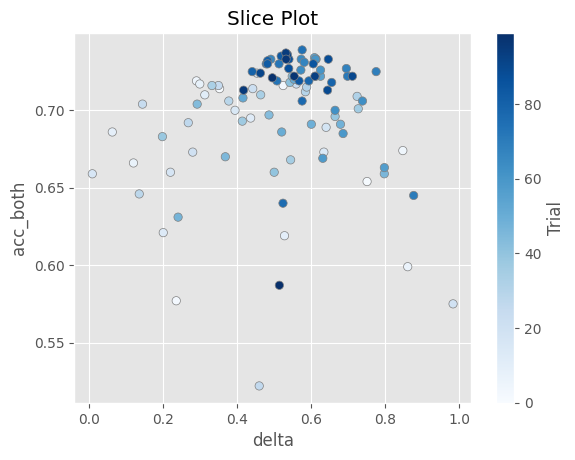

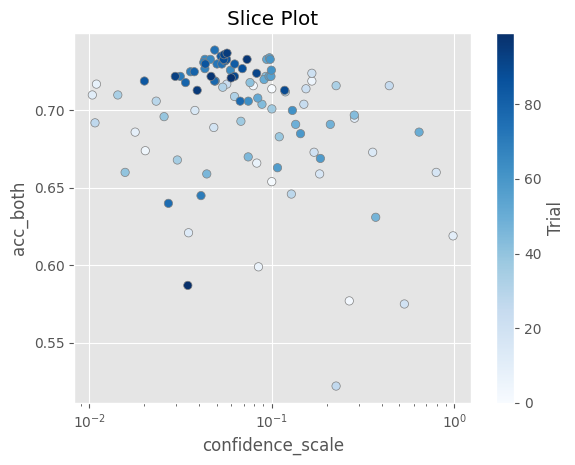

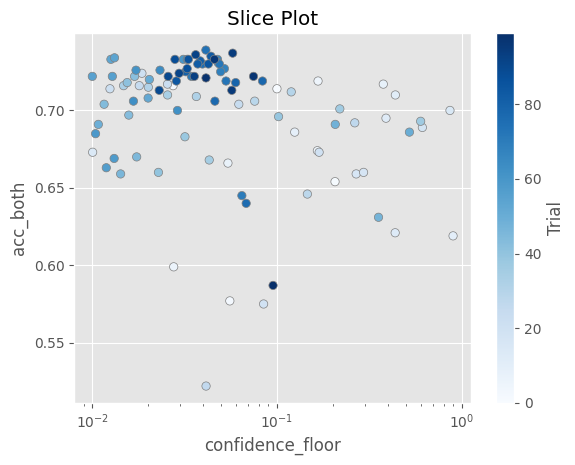

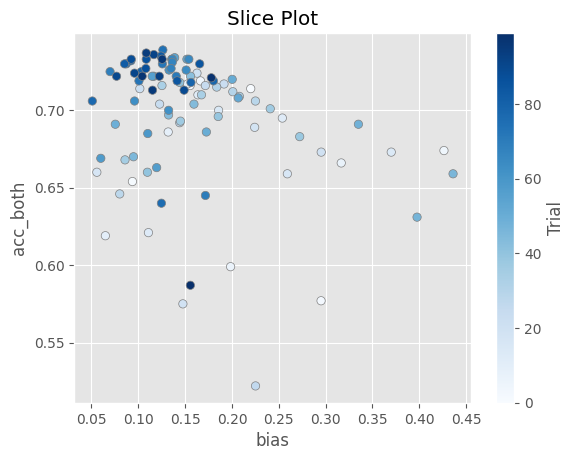

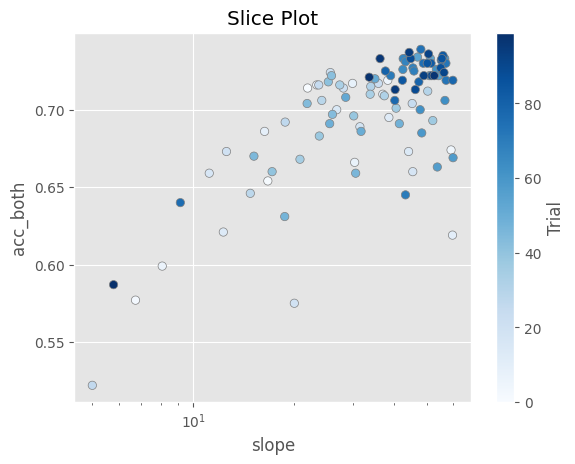

In [8]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_slice

for parameter in search_keys:
    plot_slice(study, params=[parameter], target_name=TARGET_METRIC)
    #ax.figure.set_size_inches(7, 4)
    #plt.show()
    #plt.close(ax.figure)